Importacion de LIbrerias necesarias para el EDA

In [ ]:

import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA



Vista General de Escenario


In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110

drive.mount('/content/gdrive/')
PATH ='/content/gdrive/MyDrive/TrabajoFinal/datasets/'
SCENARIO = 'S0'
df = pd.read_csv(PATH + 'dataset' + SCENARIO +'.csv')

df.head()

Drive already mounted at /content/gdrive/; to attempt to forcibly remount, call drive.mount("/content/gdrive/", force_remount=True).


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-05 13:19:02.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
1,2026-03-05 13:19:03.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
2,2026-03-05 13:19:04.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
3,2026-03-05 13:19:05.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,40

## 1. Estructura del escenario

Lo primero es saber con qué se está trabajando: cuántas filas, si el tiempo está duplicado o tiene huecos, y cómo se reparten las columnas entre dispositivos y tipos de magnitud.

In [ ]:
# --- agrupación de columnas: dispositivo, tipo, fase ---
SIG_TIPO = {
    "uln1": "Tensión fase-neutro", "uln2": "Tensión fase-neutro", "uln3": "Tensión fase-neutro",
    "ull12": "Tensión fase-fase", "ull23": "Tensión fase-fase", "ull31": "Tensión fase-fase",
    "iln1": "Corriente de fase", "iln2": "Corriente de fase", "iln3": "Corriente de fase",
    "i_sum3": "Corriente de neutro",
    "pln1": "Potencia activa", "pln2": "Potencia activa", "pln3": "Potencia activa", "p_sum3": "Potencia activa",
    "sln1": "Potencia aparente", "sln2": "Potencia aparente", "sln3": "Potencia aparente", "s_sum3": "Potencia aparente",
    "qln1": "Potencia reactiva", "qln2": "Potencia reactiva", "qln3": "Potencia reactiva", "q_sum3": "Potencia reactiva",
    "cos_phi1": "Factor de potencia", "cos_phi2": "Factor de potencia", "cos_phi3": "Factor de potencia",
    "freq": "Frecuencia",
    "phase_seq": "Secuencia de fases",
    "realtime": "Marca de tiempo del equipo",
}
UNIDAD = {
    "Tensión fase-neutro": "V", "Tensión fase-fase": "V", "Corriente de fase": "A",
    "Corriente de neutro": "A", "Potencia activa": "W", "Potencia aparente": "VA",
    "Potencia reactiva": "var", "Factor de potencia": "—", "Frecuencia": "Hz",
    "Secuencia de fases": "—", "Marca de tiempo del equipo": "s",
    "SOC": "fracción 0-1", "Señal de precio": "EUR/kWh", "Contexto de escenario": "—",
    "Control / etiquetas": "—", "Desconocido": "?",
}
FASE = {"ull12": "L1-L2", "ull23": "L2-L3", "ull31": "L3-L1"}

def partir(c):
    if "." in c:
        dev, sig = c.split(".", 1)
    else:
        dev, sig = "(sin prefijo)", c
    return dev, sig

def tipo_de(dev, sig):
    if dev == "(sin prefijo)":
        return "Control / etiquetas"
    if dev.startswith("Battery-SOC"):
        return "SOC"
    if dev == "MQTT-Price-Signal":
        return "Señal de precio"
    if dev == "Profile":
        return "Contexto de escenario"
    return SIG_TIPO.get(sig, "Desconocido")

def fase_de(sig):
    if sig in FASE:
        return FASE[sig]
    if sig.endswith("sum3"):
        return "trifásica"
    if sig.endswith("1"):
        return "L1"
    if sig.endswith("2"):
        return "L2"
    if sig.endswith("3"):
        return "L3"
    return "—"

reg = []
for c in df.columns:
    dev, sig = partir(c)
    t = tipo_de(dev, sig)
    reg.append({"columna": c, "dispositivo": dev, "señal": sig,
                "tipo": t, "unidad": UNIDAD.get(t, "?"), "fase": fase_de(sig)})
cols = pd.DataFrame(reg)

print("columnas:", len(cols), "| dispositivos:", cols.dispositivo.nunique(), "| tipos:", cols.tipo.nunique())
print("\n--- por dispositivo ---")
por_dev = (cols.groupby("dispositivo")
           .agg(columnas=("columna", "size"), tipos=("tipo", lambda s: ", ".join(sorted(set(s)))))
           .sort_values("columnas", ascending=False))
display(por_dev)

columnas: 155 | dispositivos: 10 | tipos: 15

--- por dispositivo ---


,columnas,tipos
dispositivo,,
BSS-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-B-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Substation-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-A-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
PV-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Profile,8,Contexto de escenario
(sin prefijo),4,Control / etiquetas
Battery-SOC-Reported,1,SOC
Battery-SOC-Reference,1,SOC


## 2. Datos Nulos

En este release **una celda vacía no es un cero ni un `NaN` imputado: es ausencia de valor de origen**.

In [ ]:
# --- vacíos por columna y por fila ---

num = df.select_dtypes(include=[np.number])
no_num = [c for c in df.columns if c not in num.columns]
miss = df.isna()

print(f"columnas numéricas: {len(num.columns)} | no numéricas: {len(no_num)}")
if no_num:
    print("no numéricas:", no_num)

print(f"celdas vacías: {int(miss.values.sum()):,} de {miss.size:,} ({miss.values.mean()*100:.2f} %)")
print(f"filas con algún vacío: {int((miss.sum(axis=1) > 0).sum()):,} de {len(miss):,}")

por_col = miss.mean().mul(100).sort_values(ascending=False)
con_vacios = por_col[por_col > 0]
print(f"ncolumnas con al menos un vacío: {len(con_vacios)} de {len(por_col)}")
print("\ntop 15 columnas más incompletas (%):")
print(con_vacios.head(15).round(2).to_string())


columnas numéricas: 150 | no numéricas: 5
no numéricas: ['timestamp', 'attack_active', 'attack_phase', 'attack_phase_all', 'Profile.timestamp']
celdas vacías: 482 de 278,690 (0.17 %)
filas con algún vacío: 427 de 1,798
ncolumnas con al menos un vacío: 11 de 155

top 15 columnas más incompletas (%):
MQTT-Price-Signal.price_eur_per_kwh    23.75
Profile.pv_reactive_kvar                0.33
Profile.timestamp                       0.33
Profile.pv_active_kw                    0.33
Profile.load2_kw                        0.33
Profile.load1_kw                        0.33
Profile.ambient_temperature             0.33
Profile.total_irradiance                0.33
Profile.pv_input_kw                     0.33
Battery-SOC-Reported.soc_value          0.33
Battery-SOC-Reference.soc_value         0.06


 # Eliminar columnas sin aporte
 por ahora vamos a descartar las columas que involucren marcas temporales y etapas del ataque ya que no estamos interezados en analizar estas caracteristicas.
"

In [ ]:
print(df.shape)
df = df.drop(columns=["attack_phase", "attack_phase_all","Profile.timestamp","timestamp"])
df = df.drop(columns=[c for c in df.columns if "realtime" in c ])
df = df.drop(columns=[c for c in df.columns if "phase_seq" in c ])
print(df.shape)


(1798, 155)
(1798, 141)


In [ ]:
# Identificar columnas con al menos un valor nulo
columnas_con_nulos = df.columns[df.isna().any()]


# Filtrar filas que contienen nulos y mostrar solo esas columnas
filas_nulas_reducido = df.loc[df.isna().any(axis=1), columnas_con_nulos]
filas_nulas_reducido.head()

,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,MQTT-Price-Signal.price_eur_per_kwh,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.199597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.199597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.199597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.199597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Imputacion de datos nulos por la media

In [ ]:
# 1. Irradiancia total
media_irradiance = df['Profile.total_irradiance'].mean()
df['Profile.total_irradiance'] = df['Profile.total_irradiance'].fillna(media_irradiance)

# 2. Temperatura ambiente
media_temp = df['Profile.ambient_temperature'].mean()
df['Profile.ambient_temperature'] = df['Profile.ambient_temperature'].fillna(media_temp)

# 3. Señal de precio MQTT
media_price = df['MQTT-Price-Signal.price_eur_per_kwh'].mean()
df['MQTT-Price-Signal.price_eur_per_kwh'] = df['MQTT-Price-Signal.price_eur_per_kwh'].fillna(media_price)

# 4. SOC de referencia de batería
media_soc_ref = df['Battery-SOC-Reference.soc_value'].mean()
df['Battery-SOC-Reference.soc_value'] = df['Battery-SOC-Reference.soc_value'].fillna(media_soc_ref)

# 5. SOC reportado de batería
media_soc_rep = df['Battery-SOC-Reported.soc_value'].mean()
df['Battery-SOC-Reported.soc_value'] = df['Battery-SOC-Reported.soc_value'].fillna(media_soc_rep)

# 6. Carga de perfil 1
media_load1 = df['Profile.load1_kw'].mean()
df['Profile.load1_kw'] = df['Profile.load1_kw'].fillna(media_load1)

# 7. Carga de perfil 2
media_load2 = df['Profile.load2_kw'].mean()
df['Profile.load2_kw'] = df['Profile.load2_kw'].fillna(media_load2)

media_active_kw = df['Profile.pv_active_kw'].mean()
df['Profile.pv_active_kw'] = df['Profile.pv_active_kw'].fillna(media_active_kw)

media_input_kw = df['Profile.pv_input_kw'].mean()
df['Profile.pv_input_kw'] = df['Profile.pv_input_kw'].fillna(media_input_kw)

media_reactive_kvar = df['Profile.pv_reactive_kvar'].mean()
df['Profile.pv_reactive_kvar'] = df['Profile.pv_reactive_kvar'].fillna(media_reactive_kvar)


# 3.Transformacion y codificacion
Las mediciones provistas por los cinco analizadores de red Janitza UMG 508 —28 magnitudes por dispositivo— se resumiran en 28 variables mediante la media aritmética entre puntos de medición para cada instante de muestreo. ; no preserva la resolución por punto de medición ni la dispersión entre medidores.

In [ ]:
# Definir los medidores y las señales que se repiten
medidores = [
    "BSS-Inverter-AC-Meter",
    "Load-A-AC-Meter",
    "Load-B-AC-Meter",
    "PV-Inverter-AC-Meter",
    "Substation-AC-Meter"
]

signals = [
    "uln1", "uln2", "uln3", "ull12", "ull23", "ull31",
    "iln1", "iln2", "iln3", "i_sum3",
    "pln1", "pln2", "pln3", "p_sum3",
    "sln1", "sln2", "sln3", "s_sum3",
    "qln1", "qln2", "qln3", "q_sum3",
    "cos_phi1", "cos_phi2", "cos_phi3",
    "freq", "phase_seq", "realtime"
]

# Crear un nuevo DataFrame vacío con el mismo índice que el DataFrame original
df_medias_por_fila = pd.DataFrame(index=df.index)

for sig in signals:
    # Buscar las columnas de esta señal para los 5 medidores que realmente existan en el DataFrame
    columnas_senal = [f"{medidor}.{sig}" for medidor in medidores if f"{medidor}.{sig}" in df.columns]
    if columnas_senal:
        # Calcular la media a lo largo de las columnas (eje 1) para cada fila
        df_medias_por_fila[sig] = df[columnas_senal].mean(axis=1)

# Mostrar las primeras filas del resultado obtenido manteniendo el número original de registros
print(f"Dimensiones finales del dataset combinado: {df_medias_por_fila.shape}")
display(df_medias_por_fila.head())

Dimensiones finales del dataset combinado: (1798, 26)


,uln1,uln2,uln3,ull12,ull23,ull31,iln1,iln2,iln3,i_sum3,pln1,pln2,pln3,p_sum3,sln1,sln2,sln3,s_sum3,qln1,qln2,qln3,q_sum3,cos_phi1,cos_phi2,cos_phi3,freq
0,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
1,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
2,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
3,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
4,234.335452,234.060138,234.640417,405.393713,405.973932,406.347925,1.176238,1.129897,1.127230,0.346362,-5.797341,2.649158,-3.047642,-6.195824,275.611429,264.429658,264.481614,804.522692,-102.158200,-85.330917,-81.904104,-268.702021,-0.388868,0.245911,-0.498407,50.004418


Eliminamos las columnas
 promediadas y introducimos las calculadas. Generamos un nuevo .scv para una mejor visualizacion

In [ ]:
# 1. Crear la lista de columnas antiguas de los medidores individuales para eliminarlas
columnas_a_eliminar = []
for medidor in medidores:
    for sig in signals:
        col_name = f"{medidor}.{sig}"
        if col_name in df.columns:
            columnas_a_eliminar.append(col_name)

# 2. Eliminar las columnas viejas del DataFrame original
df_limpio = df.drop(columns=columnas_a_eliminar)
# 3. Concatenar las nuevas columnas promediadas al DataFrame
df = pd.concat([df_limpio, df_medias_por_fila], axis=1)
# Mostrar el resultado final
print(f"Dimensiones del DataFrame original limpio: {df.shape}")
display(df.head())
df.to_csv('datos_completos.csv', index=False, encoding='utf-8')

Dimensiones del DataFrame original limpio: (1798, 37)


,attack_active,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,MQTT-Price-Signal.price_eur_per_kwh,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,uln1,uln2,uln3,ull12,ull23,ull31,iln1,iln2,iln3,i_sum3,pln1,pln2,pln3,p_sum3,sln1,sln2,sln3,s_sum3,qln1,qln2,qln3,q_sum3,cos_phi1,cos_phi2,cos_phi3,freq
0,False,0.035959,0.052664,-0.025255,26.2,5.995618,13.654363,-20.409331,-20.76032,9.880679,643.1,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
1,False,0.199597,0.052664,-0.025255,26.2,5.995618,13.654363,-20.409331,-20.76032,9.880679,643.1,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
2,False,0.199597,0.052664,-0.025255,26.2,5.995618,13.654363,-20.409331,-20.76032,9.880679,643.1,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
3,False,0.199597,0.052664,-0.025255,26.2,5.995618,13.654363,-20.409331,-20.76032,9.880679,643.1,235.746088,235.397858,235.965128,407.804901,408.342010,408.606232,3.730424,3.628425,3.650364,0.442819,-745.960698,-722.703443,-729.728019,-2198.392160,878.861612,853.592459,860.902397,2593.356347,258.371646,254.862172,269.166221,791.823668,-0.780956,-0.237393,-0.875574,50.007199
4,False,0.199597,0.052664,-0.025255,26.2,5.995618,13.654363,-20.409331,-20.76032,9.880679,643.1,234.335452,234.060138,234.640417,405.393713,405.973932,406.347925,1.176238,1.129897,1.127230,0.346362,-5.797341,2.649158,-3.047642,-6.195824,275.611429,264.429658,264.481614,804.522692,-102.158200,-85.330917,-81.904104,-268.702021,-0.388868,0.245911,-0.498407,50.004418


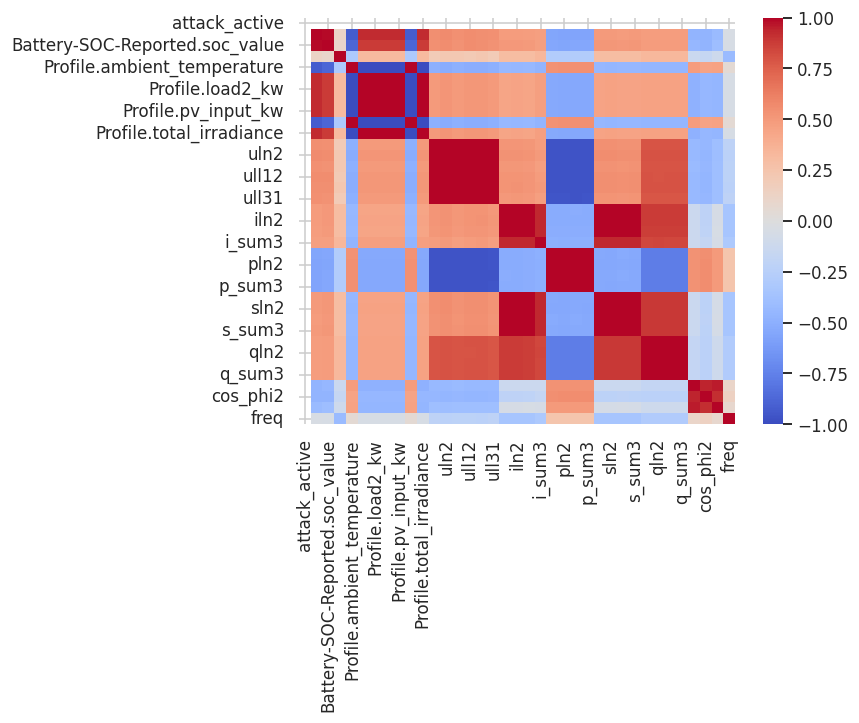

In [ ]:
import seaborn as sns
sns.heatmap(df.corr(),cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.show()

# Estandarizacion y determinacion de variable objetivo y las de entrada

In [ ]:
#Variables
Y=df["attack_active"]
X=df.drop(["attack_active"],axis=1)

#Estandarización
sc = StandardScaler()
Xs = sc.fit_transform(X)

#LDA - Modificado n_components a 1 porque la variable objetivo es binaria (2 clases: True/False)
lda = LinearDiscriminantAnalysis(n_components=1)

X_train_lda = lda.fit_transform(Xs,Y)
X_test_lda = lda.transform(Xs)

print(X_train_lda.shape)
print(X_test_lda.shape)
#importancia_lda = pd.DataFrame({ 'Columna': X.columns, 'Coeficiente': lda.scalings\.flatten() })


ValueError: n_components cannot be larger than min(n_features, n_classes - 1).

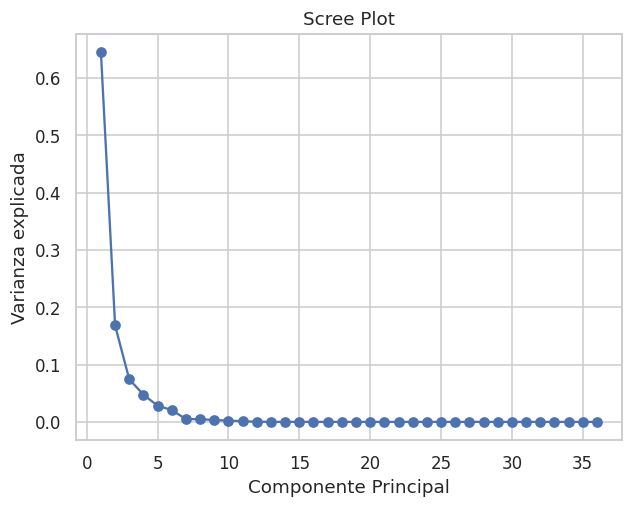

[[ 1.47931893e-01  1.48360039e-01  7.71880045e-02 ... -1.05988438e-01
  -8.00060078e-02 -7.60500889e-02]
 [-7.57332801e-02 -6.51311515e-02  4.58884214e-02 ...  2.45523736e-01
   2.93131863e-01 -6.97336800e-02]
 [-2.76844301e-01 -2.73208099e-01 -5.37961667e-02 ...  4.22614521e-01
   4.09579843e-01  4.04716330e-02]
 ...
 [-0.00000000e+00  1.14249773e-13 -2.74950351e-15 ... -1.66768053e-13
   2.04235698e-13 -5.73897589e-15]
 [ 0.00000000e+00 -2.52445486e-14 -4.42956750e-14 ...  2.47918591e-14
  -1.15345120e-14 -1.52429903e-14]
 [-0.00000000e+00  1.13133048e-14  7.93626561e-15 ...  1.14937958e-15
   1.69772444e-14  1.95173398e-14]]


In [ ]:

pca = PCA()
pca.fit(Xs)

PC_values = np.arange(pca.n_components_) + 1
explained_variance = pca.explained_variance_ratio_
plt.plot(PC_values, pca.explained_variance_ratio_, marker='o')
plt.xlabel("Componente Principal")
plt.ylabel("Varianza explicada")
plt.title("Scree Plot")
plt.show()
print(pca.components_)
pd.DataFrame(pca.components_).to_csv("componentes_pca.csv", index=False)

df_2 = pd.DataFrame(
    pca.components_,                                  # nombres de tus columnas originales
    index=[f"PC{i+1}" for i in range(pca.components_.shape[0])]
)
df_2.to_csv("pca_components_matriz.csv")

In [ ]:
# relacion = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8'], index=df.columns)
# print(relacion)

## 3. Distribuciones

Una grilla por bloque de 40 columnas. Sirve para detectar de un vistazo las constantes (sin varianza), las bimodales, las truncadas y las que tienen escala absurda. Las columnas constantes se excluyen del gráfico y se listan arriba.

In [ ]:
# Graficar las columnas de X de manera simple
import matplotlib.pyplot as plt

# Configuramos una cuadrícula para graficar las columnas del DataFrame X
columns_to_plot = X.columns
n_cols = 3
n_rows = (len(columns_to_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 2 * n_rows))
axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    axes[i].hist(X[col].dropna(), bins=30, color='tab:blue', alpha=0.7)
    axes[i].set_title(col, fontsize=8)
    axes[i].tick_params(axis='both', which='major', labelsize=7)

# Ocultar subplots vacíos
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr

t = np.arange(len(df))

# features numéricas, sin timestamp
num = df.drop(columns=["timestamp"], errors="ignore").select_dtypes("number")

# ---- 1. métricas por columna ----
rep = []
for c in num.columns:
    x = num[c]
    m = x.notna()
    if m.sum() < 10 or x[m].nunique() < 2:
        continue
    rho = spearmanr(x[m], t[m]).correlation          # monotonía vs tiempo
    pear = np.corrcoef(x[m], t[m])[0, 1]             # tendencia lineal
    d = np.sign(x[m].diff().dropna()); d = d[d != 0]
    mono = abs(d.sum()) / len(d) if len(d) else np.nan  # 1.0 = monotónico puro
    rep.append({"col_pos": list(df.columns).index(c) + 1, "column": c,
                "spearman": rho, "pearson": pear, "mono": mono,
                "abs_rho": abs(rho)})

rep = pd.DataFrame(rep).sort_values("abs_rho", ascending=False)
print(rep.head(20).to_string(index=False))
print("\n|rho|>0.9:", (rep.abs_rho > 0.9).sum(), "/", len(rep))

 col_pos                              column  spearman   pearson     mono  abs_rho
       2     Battery-SOC-Reference.soc_value -0.903936 -0.792175 0.678284 0.903936
       4 MQTT-Price-Signal.price_eur_per_kwh -0.772121 -0.614153 0.000000 0.772121
       3      Battery-SOC-Reported.soc_value -0.740734 -0.771544 0.506276 0.740734
      27                                sln2 -0.591303 -0.564068 0.008658 0.591303
      26                                sln1 -0.589963 -0.563470 0.025974 0.589963
      29                              s_sum3 -0.589455 -0.562480 0.000000 0.589455
      23                                pln2  0.587422  0.579654 0.043290 0.587422
      28                                sln3 -0.586578 -0.559698 0.034632 0.586578
      19                                iln2 -0.585772 -0.557878 0.004329 0.585772
      18                                iln1 -0.585028 -0.557330 0.021645 0.585028
      25                              p_sum3  0.584971  0.578265 0.043290 0.584971
    

## 5. Correlación

Tres vistas del mismo cálculo:

1. **Matriz numérica completa** — el DataFrame entero, exportable a CSV.
2. **Heatmap con clustering jerárquico** — revela los bloques sin imponerlos.
3. **Top 30 de pares** — el detalle numérico de lo que el heatmap sugiere.

Se usa Pearson sobre pares completos (`min_periods=30`). Las columnas constantes se excluyen del heatmap porque su correlación es indefinida.

**Por qué la matriz no es de 156×156:** de las 155 columnas fuera de `timestamp`, solo 150 son numéricas. Las otras 5 son texto o etiquetas y una correlación sobre ellas no significa nada. Los casos, en todos los escenarios, son `attack_active` (booleana: es la etiqueta, incluirla filtra el ataque en el heatmap), `attack_phase`, `attack_phase_all`, `Profile.timestamp` (cadena de texto, no es la hora de la fila) y, solo en S6, `MQTT-Price-Signal.event`.

In [ ]:
# --- matriz numérica ---
corr = X.corr(method="pearson", min_periods=30)
print("columnas numéricas:", df.shape[1], "-> matriz", corr.shape)
print("pares con correlación calculable:", int(corr.notna().values.sum() - len(corr)))
print("celdas sin definir (NaN), por columnas constantes en su intersección:", int(corr.isna().values.sum()))

with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(corr.round(3))

In [ ]:
nunique = num.nunique(dropna=True)
con_var = [c for c in num.columns if nunique[c] > 1]
excluidas = [c for c in num.columns if nunique[c] <= 1]
print(f"{len(con_var)} columnas con varianza | {len(excluidas)} constantes excluidas")
if excluidas:
    print("excluidas:", excluidas)

c = num[con_var].corr(method="pearson", min_periods=30)

plt.figure(figsize=(17, 17))
ax = sns.heatmap(
    c, cmap="RdBu_r",
    center=0, vmin=-1, vmax=1,
    linewidths=0, cbar_kws={"label": "Pearson"}
)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=5, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=5)
plt.title(f"Correlación — {SCENARIO}", fontsize=13, pad=20)
plt.tight_layout()
plt.show()

In [ ]:
# --- top 30 pares más correlacionados ---
iu = np.triu_indices_from(corr, k=1)
pares = pd.DataFrame({
    "a": corr.index[iu[0]],
    "b": corr.columns[iu[1]],
    "r": corr.values[iu],
}).dropna(subset=["r"])
pares["abs_r"] = pares.r.abs()
pares = pares.sort_values("abs_r", ascending=False).head(30).reset_index(drop=True)
pares["n_pares"] = [int(num[[r.a, r.b]].dropna().shape[0]) for r in pares.itertuples()]
meta_c = cols.set_index("columna")
pares["tipo_a"] = pares.a.map(meta_c.tipo)
pares["tipo_b"] = pares.b.map(meta_c.tipo)
pares["dispositivo_a"] = pares.a.map(meta_c.dispositivo)
pares["dispositivo_b"] = pares.b.map(meta_c.dispositivo)
pares["mismo_dispositivo"] = pares.dispositivo_a == pares.dispositivo_b

pd.set_option("display.float_format", lambda v: f"{v:.6f}")
display(pares[["a", "b", "r", "n_pares", "mismo_dispositivo", "tipo_a", "tipo_b"]])
pd.reset_option("display.float_format")

n_mismo = int(pares.mismo_dispositivo.sum())
print(f"de los 30 pares, {n_mismo} son del mismo medidor y {30 - n_mismo} cruzan dispositivos.")
print("Las fases de un medidor se mueven casi en fase (r ~ 0.99999), por eso dominan el ranking.")

cruzados = pares[~pares.mismo_dispositivo].head(5)
if len(cruzados):
    print("\ntop 5 pares entre dispositivos distintos:")
    for r in cruzados.itertuples():
        print(f"  {r.a:38s} <-> {r.b:38s} r={r.r:+.6f}  n={r.n_pares}")
else:
    print("\nno hay pares entre dispositivos distintos en el top 30.")

## 6. Notas para interpretar este dataset

- **Celda vacía ≠ 0.** Es ausencia de valor de origen. No imputar: si llenás con cero, el heatmap se llena de correlaciones espurias.
- **`Profile.timestamp` no es la hora de la fila.** Es un reloj fijo de laboratorio repetido en bloques. Para el tiempo real usá la columna `timestamp`.
- **`realtime` solo sirve en el medidor de subestación.** En los otros cuatro es un valor constante repetido.
- **`phase_seq` es constante** en todo el release: no aporta como feature.
- **`S² = P² + Q²` no cierra.** `s` es la potencia total (con armónicos) pero `p` y `q` son solo fundamentales. No lo uses como validación de integridad.
- **S6 tiene 156 columnas, el resto 155.** La diferencia es `MQTT-Price-Signal.event`. Si comparás escenarios, alineá por nombre, nunca por posición.
- **Ojo con los bloques pegados.** En S4 las últimas 602 filas tienen la potencia activa de ambos medidores de carga clavada en `20000.0` mientras tensión y corriente siguen normales: es un bloque de driver, no una medición.

In [ ]:
# --- exportación opcional (desactivada por defecto) ---
GUARDAR = False
OUT_DIR = os.path.join(DATA_DIR, "_eda_salida")

if GUARDAR:
    os.makedirs(OUT_DIR, exist_ok=True)
    base = f"{SCENARIO}_"
    corr.round(4).to_csv(os.path.join(OUT_DIR, base + "correlacion.csv"))
    pares.to_csv(os.path.join(OUT_DIR, base + "top_pares.csv"), index=False)
    cols.to_csv(os.path.join(OUT_DIR, base + "columnas.csv"), index=False)
    print("guardado en", OUT_DIR)
else:
    print("Exportación desactivada. Poné GUARDAR = True para escribir los CSV en Drive.")